In [1]:
import geopandas as gpd
import pandas as pd

# 1. Leer el archivo GeoJSON
gdf = gpd.read_file("export.geojson")

# 2. Imprimir información básica del dataset
print(f"Total de registros encontrados: {len(gdf)}")
print("\nColumnas disponibles en el archivo:")
print(gdf.columns.tolist())

# 3. Mostrar las primeras 5 filas completas
gdf.head()

Total de registros encontrados: 12570

Columnas disponibles en el archivo:
['id', '@id', 'abandoned', 'abandoned:building', 'access', 'addr:city', 'addr:full', 'addr:housenumber', 'addr:place', 'addr:postcode', 'addr:street', 'addr:suburb', 'alt_name', 'alt_name:es', 'amenity', 'architect', 'area', 'barrier', 'bench', 'bic:inscription_date', 'branch', 'building', 'building:colour', 'building:levels', 'building:levels:underground', 'building:material', 'building:part', 'bus', 'capacity', 'check_date', 'construction', 'construction_date', 'converter', 'covered', 'departures_board', 'description', 'designation', 'distance', 'disused', 'disused:barrier', 'disused:building', 'disused:power', 'ele', 'entrance', 'fence_type', 'fixme', 'frequency', 'frequency_conversion', 'gas_insulated', 'generator:output:electricity', 'hazard', 'height', 'heritage', 'heritage:name', 'heritage:operator', 'heritage:website', 'highway', 'historic', 'historic:period', 'image', 'indoor', 'industrial', 'lamp_mount

,id,@id,abandoned,abandoned:building,access,addr:city,addr:full,addr:housenumber,addr:place,addr:postcode,...,wall,website,wikidata,wikimedia_commons,wikipedia,window,windows,works,year_of_construction,geometry
0,relation/1135500,relation/1135500,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-5.67495 40.9674, -5.67451 40.96773,..."
1,relation/3187758,relation/3187758,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-8.43524 43.3695, -8.43502 43.36934,..."
2,relation/3581007,relation/3581007,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"POLYGON ((-3.7135 40.31265, -3.71396 40.31273,..."
3,relation/4503662,relation/4503662,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"POLYGON ((2.77823 42.12096, 2.77823 42.12088, ..."
4,relation/4510090,relation/4510090,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,"POLYGON ((2.80612 41.97311, 2.80609 41.97307, ..."


In [2]:
import json
import pandas as pd

# 1. Cargar el GeoJSON como diccionario
with open("export.geojson", "r", encoding="utf-8") as f:
    datos_json = json.load(f)

# 2. Normalizar las propiedades (tags de OpenStreetMap)
# Cada elemento en un GeoJSON tiene un diccionario 'properties'
df = pd.json_normalize([feature["properties"] for feature in datos_json["features"]])

# 3. Mostrar tamaño y columnas principales
print(f"Dimensiones de la tabla: {df.shape}")
df.head()

Dimensiones de la tabla: (12570, 164)


,@id,location,name,operator,operator:wikidata,power,source,source:date,type,substation,...,shelter,year_of_construction,construction_date,abandoned:building,leaf_type,natural,species,amenity,lamp_mount,ruined
0,relation/1135500,outdoor,ST Salamanca,Iberdrola,Q1437502,substation,ITACyL,2009,multipolygon,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,relation/3187758,NaN,SET San Pedro de Visma,UFD,NaN,substation,NaN,NaN,multipolygon,distribution,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,relation/3581007,surface,Subestación Getafe,Iberdrola,Q1437502,substation,NaN,NaN,multipolygon,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,relation/4503662,NaN,Subestació de Banyoles,NaN,NaN,substation,NaN,NaN,multipolygon,transmission,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,relation/4510090,NaN,NaN,NaN,NaN,substation,NaN,NaN,multipolygon,minor_distribution,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
columnas = [c for c in ['name', 'voltage', 'operator', 'substation'] if c in gdf.columns]
gdf[columnas].dropna(how='all').head(10)

,name,voltage,operator,substation
0,ST Salamanca,None,Iberdrola,None
1,SET San Pedro de Visma,66000;15000,UFD,distribution
2,Subestación Getafe,None,Iberdrola,None
3,Subestació de Banyoles,66000;25000,None,transmission
4,None,None,None,minor_distribution
6,None,45000;20000,None,industrial
7,SET Santa Quitería,220000;20000,None,None
8,None,25000,AgriEnergia Electrica,None
10,None,None,None,distribution
11,None,None,EDP,distribution


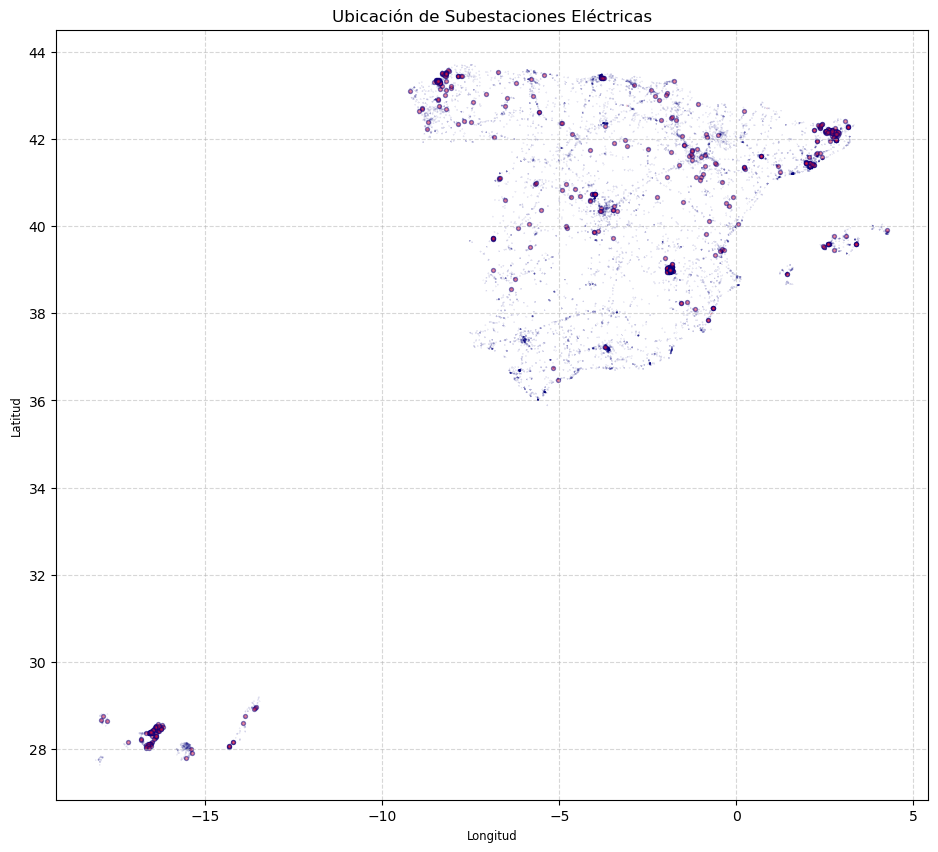

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt

gdf = gpd.read_file("export.geojson")

fig, ax = plt.subplots(figsize=(12, 10))
gdf.plot(ax=ax, markersize=8, color="crimson", alpha=0.5, edgecolor="navy")
plt.title("Ubicación de Subestaciones Eléctricas")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()